# fixAR-IRLS vs AR-iRRR, single subject: trained on run 1 vs trained on all runs

This notebook summarizes two scripts, for all subjects that have been run:

| Part | Script | Training data | Scoring | Whitening |
|---|---|---|---|---|
| **A** | `cmp_fixAR-IRLS_AR-iRRR_single-subj_single-run.py` | `gradcpt1` | train (`gradcpt1`) and test (`gradcpt2`, `gradcpt3`) | before truncation, kernel from `gradcpt1` |
| **B** | `cmp_fixAR-IRLS_AR-iRRR_single-subj_all-runs.py` | `gradcpt1` + `gradcpt2` + `gradcpt3` | in-sample only, per run and pooled | after truncation, kernel from all runs |

Each script fits two models (**fixAR-IRLS** and **AR-iRRR**) for two design matrices, using the same fNIRS data `Y`:

| Design | Regressors | Saved as |
|---|---|---|
| **Cz EEG delay regressors** | continuous Cz EEG, 0–15 s delay taps projected on 15 cubic B-splines | A: `{subject}_cont_EEG_cz_preWhiten_train-gradcpt1_cmp_fixAR-IRLS_AR-iRRR.pkl`<br>B: `{subject}_cont_EEG_cz_postWhiten_train-allRuns_cmp_fixAR-IRLS_AR-iRRR.pkl` |
| **mnt-correct Gaussian kernels** | 12 consecutive Gaussian kernels (−2 to 10 s) locked to mnt-correct onsets | A: `{subject}_mnt-correct_gauss_preWhiten_train-gradcpt1_cmp_fixAR-IRLS_AR-iRRR.pkl`<br>B: `{subject}_mnt-correct_gauss_postWhiten_train-allRuns_cmp_fixAR-IRLS_AR-iRRR.pkl` |

Contents:

**Part A: trained on `gradcpt1`, tested on `gradcpt2/3`**
1. Pipeline
2. Fit summary: `Y_scale`, the selected iRRR λ₁, and the ranks
3. Train vs test performance (R², PMSE) per subject
4. iRRR rank sweep: R² and PMSE as a function of rank
5. Per-parcel test R², including brain-surface maps
6. HRFs at the plot parcel and the 3 parcels nearest to Cz
7. Shared temporal components of the rank-2 iRRR fit
8. Observations (Part A)

**Part B: trained on all runs (in-sample)**

9. What changes in the pipeline
10. Fit summary
11. In-sample performance per run and pooled
12. iRRR rank sweep (in-sample)
13. Per-parcel in-sample R² on the brain surface
14. HRFs, and how well they agree with the Part A HRFs
15. Shared temporal components of the rank-2 iRRR fit
16. Observations (Part B)

# Part A: trained on `gradcpt1`, tested on `gradcpt2` and `gradcpt3`

## 1. Pipeline

### 1a. Inputs
- **fNIRS**: parcel time series from image reconstruction (probe Adot v26, `derivatives/cedalion/pipeline_reorder/processed_data`), **HbO** only. The script keeps parcels with forward-model sensitivity `log10(Σ_channel A) > −2`. It drops the medial wall and the `scalp` parcel, and any parcel that is not finite in all three runs. This leaves **417 parcels** for every subject.
- **EEG**: continuous EEG from `utils.eeg_preproc_subj_level`, channel **Cz**. A subject is skipped if Cz was removed in any run.
- **Run matching**: each EEG run (`gradcpt1/2/3`) is matched to its fNIRS run by the first event onset. The EEG→fNIRS time offset comes from the two events files.

### 1b. Per-run preprocessing (each run separately, *before* truncation)
1. **Highpass** the full fNIRS run: 4th-order Butterworth, 0.02 Hz, zero-phase (`sosfiltfilt`).
2. **Crop** to the span covered by EEG. The span starts 15 s (`len_delay`) after the EEG starts, so that every fNIRS sample has a full 15 s of EEG history.
3. **Drift**: OLS-regress out 3rd-order Legendre polynomials.
4. **GSR**: OLS-regress out the global mean (computed from the drift residuals).
5. **Regressors** on the same span:
   - *Cz EEG design*: Cz is convolved with a 15-s, 15-column cubic B-spline basis over the delay axis (EEG rate). The result is resampled to the fNIRS rate. Each column is one B-spline weight of a 15-s FIR "HRF".
   - *mnt-correct design*: `cedalion` Gaussian kernels (`t_pre` = 2 s, `t_post` = 10 s, Δ = 1 s, σ = 1 s, giving 12 regressors) at the onsets of mountain trials with a correct withhold (`trial_type == 'mnt'`, `response_code == 0`).
6. Record the **trial window** [first event onset, last event onset + 15 s] for step 1c.

### 1c. Whitening, truncation, scaling
1. **Noise model from the training run only**: OLS of `Y ~ 1 + X` over the full span of `gradcpt1`. The residual autocorrelation is estimated up to lag √n, Tukey-tapered, and averaged across parcels in the frequency domain. This gives **one spectral whitening filter `W`**, shared by all parcels. (`W` depends on the design, because the residuals depend on `X`.)
2. Apply the *same* `W` to `Y` and `X` of **every** run, over the run's full span. The kernel is rebuilt at each run's length.
3. **Truncate** each whitened run to its trial window.
4. **Scale**: divide `W·Y` of every run by `Y_scale` = std of the whitened training `Y`. All metrics below are in these units, so a PMSE of 1 is about the variance of the training data.

### 1d. Models (both fit on whitened `gradcpt1` only)
- **fixAR-IRLS**: robust regression per parcel (`statsmodels` RLM, Tukey biweight, c = 4.685), **no intercept**. Coefficient matrix `C` (regressor × parcel), full rank (15 or 12).
- **AR-iRRR**: `irrr_normal` with one predictor group: `min ½‖Y − 1μᵀ − XC‖² + λ₁·w·‖C‖_*`, with `w = σ_max(X_c)(√p + √rank X_c)/n`. Because of the nuclear-norm penalty, the HRFs of all parcels are combinations of a few shared temporal components.
  - λ₁ is scanned over 10^[−3, 2] (41 values). The **smallest λ₁ that gives rank 2** is used. If no grid value gives rank 2, the script bisects on log λ₁.
  - λ₁ is chosen by the **rank target, not by cross-validation**, so the test runs play no part in choosing it.

### 1e. Metrics (computed on whitened, truncated, scaled data)
- **PMSE** = mean squared residual over all time points and parcels.
- **R²** (pooled) = 1 − Σ residual² / Σ (Y − parcel mean)². **Per-parcel R²** is the same computation for each parcel separately.
- fixAR-IRLS predicts `X C`. AR-iRRR predicts `X C + μ`.
- The test R² can be negative: then the model predicts the held-out run worse than that run's own parcel means.
- **HRF** = basis · C · `Y_scale`, in M per V of Cz (EEG design) or M (mnt-correct design).

In [1]:
%matplotlib inline
import os, sys, glob, pickle
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import pyvista as pv
pv.OFF_SCREEN = True

sys.path.insert(0, os.getcwd())
from params_setting import *
import cedalion.dot
from cedalion.vis.anatomy.image_recon import image_recon, image_recon_multi_view
from cedalion.vis.blocks import plot_labeled_points

train_run = 'gradcpt1'
test_runs = ['gradcpt2', 'gradcpt3']
run_keys = [train_run] + test_runs
select_chromo = 'HbO'
plot_parcels = ['DefaultA_PFCd_1_LH']   # same as in the script
n_cz_parcels = 3

designs = {   # design label -> model_name used in the saved file
    'Cz EEG delay regressors':      f'cont_EEG_cz_preWhiten_train-{train_run}',
    'mnt-correct Gaussian kernels': f'mnt-correct_gauss_preWhiten_train-{train_run}',
}
models = ['fixAR-IRLS', 'AR-iRRR']
colors = {'fixAR-IRLS': '#2a78d6', 'AR-iRRR': '#d6336c'}
markers = {'fixAR-IRLS': 'o', 'AR-iRRR': 's'}
run_styles = {'gradcpt1': '-', 'gradcpt2': '--', 'gradcpt3': ':'}

eeg_der_dir = os.path.join(project_path, 'derivatives', 'eeg')
fig_dir = os.path.join(eeg_der_dir, 'HRF_surf', 'group', 'cmp_fixAR-IRLS_AR-iRRR_single-subj')
os.makedirs(fig_dir, exist_ok=True)

# subjects that have results for both designs
subjects = sorted(
    s for s in {os.path.basename(os.path.dirname(f)) for f in glob.glob(os.path.join(eeg_der_dir, 'sub-*', '*_cmp_fixAR-IRLS_AR-iRRR.pkl'))}
    if all(os.path.exists(os.path.join(eeg_der_dir, s, f'{s}_{mn}_cmp_fixAR-IRLS_AR-iRRR.pkl')) for mn in designs.values())
)
res = {d: {} for d in designs}   # design -> subject -> results dict
for d, mn in designs.items():
    for s in subjects:
        with open(os.path.join(eeg_der_dir, s, f'{s}_{mn}_cmp_fixAR-IRLS_AR-iRRR.pkl'), 'rb') as f:
            res[d][s] = pickle.load(f)
        assert res[d][s]['train_run'] == train_run and list(res[d][s]['test_runs']) == test_runs
parcels = res['Cz EEG delay regressors'][subjects[0]]['parcels']
assert all(np.array_equal(res[d][s]['parcels'], parcels) for d in designs for s in subjects)
subj_colors = dict(zip(subjects, plt.get_cmap('tab10').colors))
print(f'{len(subjects)} subjects: {subjects}; {len(parcels)} parcels')

6 subjects: ['sub-670', 'sub-695', 'sub-721', 'sub-723', 'sub-726', 'sub-730']; 417 parcels


## 2. Fit summary
- `Y_scale` is the std of the whitened training `Y`, in M.
- `irrr_lam1` is the selected λ₁. `bisected` marks a λ₁ found by bisection, i.e. one that is not on the grid.
- `rank` is the rank of each model's coefficient matrix.

In [2]:
grid = 10 ** np.arange(-3, 2.01, 0.125)
fit_rows = []
for d in designs:
    for s in subjects:
        r = res[d][s]
        fit_rows.append({'design': d, 'subject': s, 'Y_scale (M)': r['Y_scale'],
                         'n regressors': len(r['regressors']),
                         'IRLS rank': r['irls']['rank'], 'irrr_lam1': r['irrr']['irrr_lam1'],
                         'bisected': not np.isclose(grid, r['irrr']['irrr_lam1']).any(),
                         'iRRR rank': np.linalg.matrix_rank(r['irrr']['C'])})
fit_df = pd.DataFrame(fit_rows).set_index(['design', 'subject'])
display(fit_df.style.format({'Y_scale (M)': '{:.3g}', 'irrr_lam1': '{:.3g}'}))

## 3. Train vs test performance

Each subject has one line per model, running from the training run to the two test runs. The two designs are the two columns.
- **R²** is pooled over parcels.
- **PMSE** is divided by the PMSE of the rank-0 iRRR fit on the same run (C = 0, so Ŷ = μ, the training mean, which is ≈ 0 after whitening). A value below 1 means the regressors predict better than no regressors at all. The raw PMSE mostly tracks how noisy each run is: test runs have a different variance than `Y_scale`.

The tables below give the values, and the difference AR-iRRR − fixAR-IRLS on the test runs (mean of `gradcpt2` and `gradcpt3`).

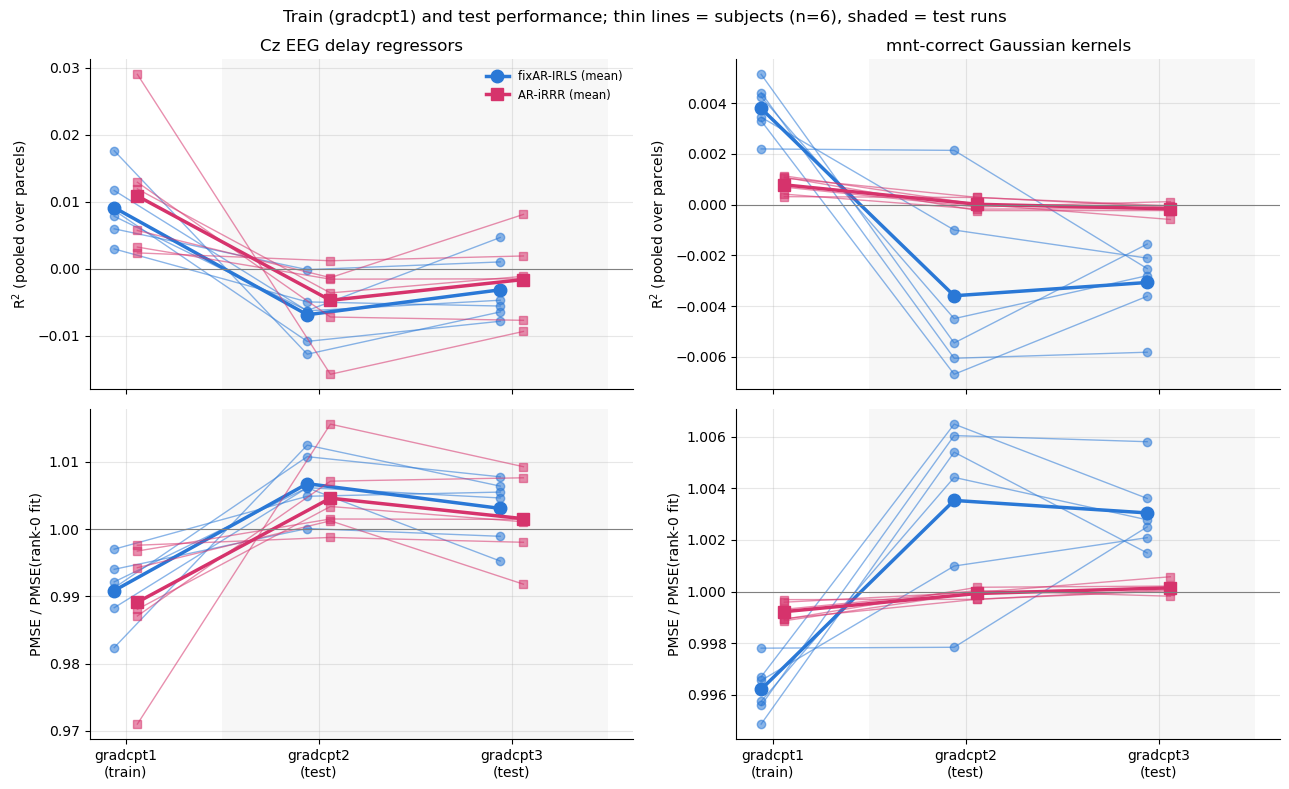

In [3]:
def null_pmse(r, run_key):
    """PMSE of the rank-0 iRRR fit (C = 0, Ŷ = μ, the training mean) on one run."""
    return next(f for f in r['irrr_scan'] if f['rank'] == 0)['metrics'][run_key]['PMSE']

perf_rows = []
for d in designs:
    for s in subjects:
        r = res[d][s]
        for mdl, key in [('fixAR-IRLS', 'irls'), ('AR-iRRR', 'irrr')]:
            for rk in run_keys:
                m = r[key]['metrics'][rk]
                perf_rows.append({'design': d, 'subject': s, 'model': mdl, 'run': rk,
                                  'set': 'train' if rk == train_run else 'test',
                                  'R2': m['R2'], 'PMSE': m['PMSE'], 'rel PMSE': m['PMSE'] / null_pmse(r, rk),
                                  'median parcel R2': np.median(m['R2_parcel'])})
perf_df = pd.DataFrame(perf_rows)

fig, axes = plt.subplots(2, len(designs), figsize=(6.5 * len(designs), 8), sharex=True)
x = np.arange(len(run_keys))
for c, d in enumerate(designs):
    for row, (metric, ylab) in enumerate([('R2', 'R$^2$ (pooled over parcels)'), ('rel PMSE', 'PMSE / PMSE(rank-0 fit)')]):
        ax = axes[row, c]
        for mdl in models:
            for s in subjects:
                v = perf_df.query('design == @d and subject == @s and model == @mdl').set_index('run').loc[run_keys, metric]
                ax.plot(x + (-0.06 if mdl == 'fixAR-IRLS' else 0.06), v.values, color=colors[mdl], marker=markers[mdl],
                        ms=6, lw=1, alpha=0.55)
            mean = perf_df.query('design == @d and model == @mdl').groupby('run')[metric].mean().loc[run_keys]
            ax.plot(x + (-0.06 if mdl == 'fixAR-IRLS' else 0.06), mean.values, color=colors[mdl], marker=markers[mdl],
                    ms=9, lw=2.5, label=f'{mdl} (mean)')
        ax.axhline(0 if metric == 'R2' else 1, color='gray', lw=0.8)
        ax.axvspan(0.5, 2.5, color='gray', alpha=0.06, lw=0)
        ax.grid(True, alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
        ax.set_ylabel(ylab)
        if row == 0:
            ax.set_title(d)
    axes[1, c].set_xticks(x, [f"{rk}\n({'train' if rk == train_run else 'test'})" for rk in run_keys])
axes[0, 0].legend(frameon=False, fontsize='small')
fig.suptitle(f'Train ({train_run}) and test performance; thin lines = subjects (n={len(subjects)}), shaded = test runs')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'train_test_R2_PMSE.png'), dpi=150)
plt.show()

In [4]:
pd.set_option('display.float_format', lambda v: f'{v:.4g}')
tbl = perf_df.pivot_table(index=['design', 'subject'], columns=['model', 'run'], values='R2')
display(tbl.style.format('{:.4f}').set_caption('Pooled R² per run').background_gradient(cmap='RdBu_r', vmin=-0.02, vmax=0.02, axis=None))

test = perf_df[perf_df.set == 'test'].groupby(['design', 'subject', 'model'])[['R2', 'rel PMSE']].mean().unstack('model')
diff = pd.DataFrame({'test R2: fixAR-IRLS': test[('R2', 'fixAR-IRLS')], 'test R2: AR-iRRR': test[('R2', 'AR-iRRR')],
                     'ΔR2 (iRRR − IRLS)': test[('R2', 'AR-iRRR')] - test[('R2', 'fixAR-IRLS')],
                     'Δ rel PMSE (iRRR − IRLS)': test[('rel PMSE', 'AR-iRRR')] - test[('rel PMSE', 'fixAR-IRLS')]})
r2_cols = ['test R2: fixAR-IRLS', 'test R2: AR-iRRR', 'ΔR2 (iRRR − IRLS)']
lim_r2 = np.abs(diff[r2_cols].values).max()
lim_pmse = np.abs(diff['Δ rel PMSE (iRRR − IRLS)'].values).max()
display(diff.style.format('{:.4f}')
        .background_gradient(cmap='RdBu_r', vmin=-lim_r2, vmax=lim_r2, subset=r2_cols, axis=None)
        .background_gradient(cmap='RdBu', vmin=-lim_pmse, vmax=lim_pmse, subset=['Δ rel PMSE (iRRR − IRLS)'])
        .set_caption('Mean over the two test runs. R² columns: red = positive. Δ columns: red = AR-iRRR better '
                     '(higher R², lower PMSE), blue = fixAR-IRLS better'))
print('Subjects where AR-iRRR has the higher test R2:')
print((diff['ΔR2 (iRRR − IRLS)'] > 0).groupby('design').agg(['sum', 'count']).to_string())

Subjects where AR-iRRR has the higher test R2:
                              sum  count
design                                  
Cz EEG delay regressors         4      6
mnt-correct Gaussian kernels    6      6


## 4. iRRR rank sweep

The λ₁ scan gives a family of iRRR fits of decreasing rank. Each rank is represented by its smallest-λ₁ fit, the same rule used to pick λ₁. The plots show R² and the relative PMSE (as in section 3) against rank, for the training run (solid) and the mean of the two test runs (dashed). One color per subject. The red dashed line is the chosen rank (2), and ✕ marks fixAR-IRLS at its full rank.

Where the dashed (test) curves peak shows which rank generalizes best. A test curve that falls as rank grows means the extra components fit noise in `gradcpt1`.

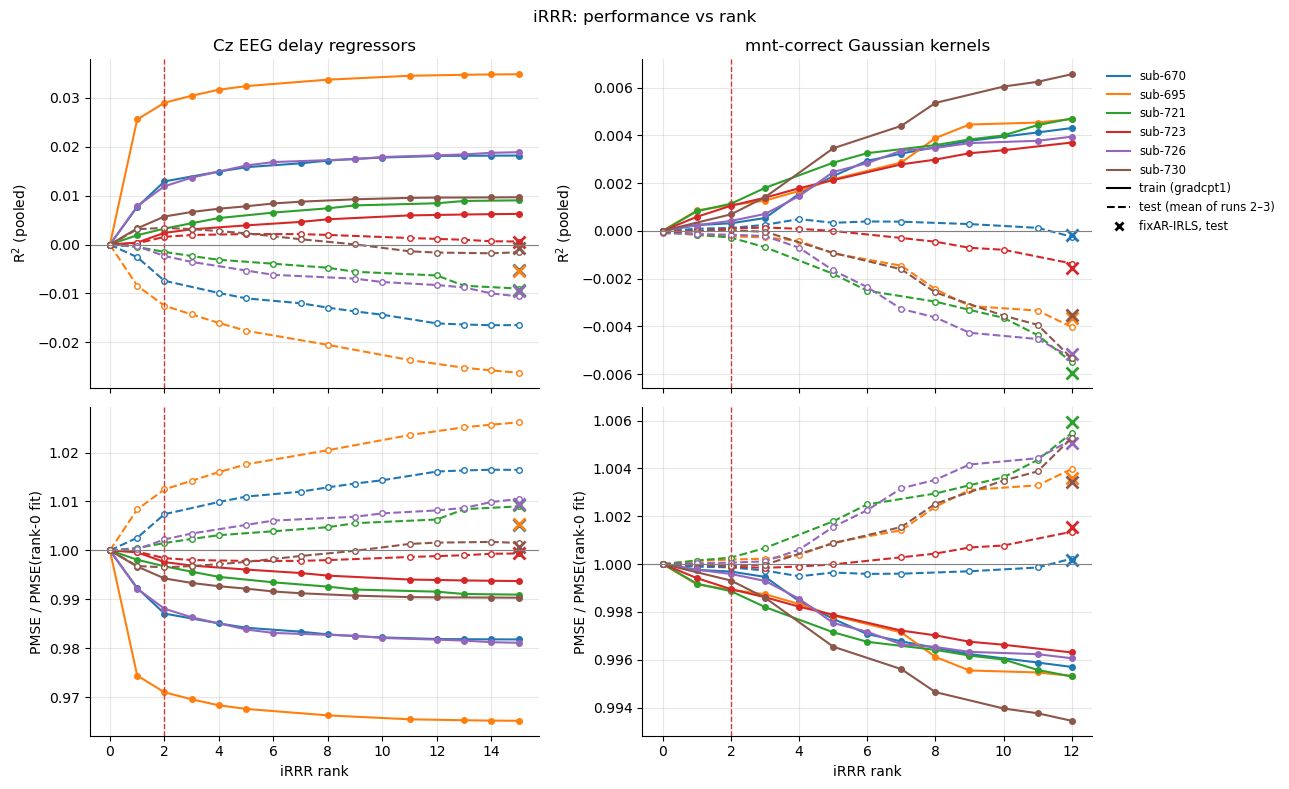

In [5]:
def best_per_rank(scan):
    out = {}
    for f in scan:
        if f['rank'] not in out or f['lam1'] < out[f['rank']]['lam1']:
            out[f['rank']] = f
    return dict(sorted(out.items()))

fig, axes = plt.subplots(2, len(designs), figsize=(6.5 * len(designs), 8), sharex='col')
for c, d in enumerate(designs):
    for row, metric in enumerate(['R2', 'rel PMSE']):
        ax = axes[row, c]
        for s in subjects:
            r = res[d][s]
            bpr = best_per_rank(r['irrr_scan'])
            rk_list = list(bpr)
            def val(m, rk):
                return m[rk]['R2'] if metric == 'R2' else m[rk]['PMSE'] / null_pmse(r, rk)
            tr = [val(bpr[k]['metrics'], train_run) for k in rk_list]
            te = [np.mean([val(bpr[k]['metrics'], rk) for rk in test_runs]) for k in rk_list]
            ax.plot(rk_list, tr, color=subj_colors[s], lw=1.5, marker='o', ms=4, label=s)
            ax.plot(rk_list, te, color=subj_colors[s], lw=1.5, ls='--', marker='o', ms=4, mfc='white')
            irls_te = np.mean([val(r['irls']['metrics'], rk) for rk in test_runs])
            ax.plot(r['irls']['rank'], irls_te, marker='x', ms=9, mew=2, color=subj_colors[s], ls='none')
        ax.axvline(2, color='#d03b3b', ls='--', lw=1)
        ax.axhline(0 if metric == 'R2' else 1, color='gray', lw=0.8)
        ax.grid(True, alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
        ax.set_ylabel('R$^2$ (pooled)' if metric == 'R2' else 'PMSE / PMSE(rank-0 fit)')
        if row == 0:
            ax.set_title(d)
    axes[1, c].set_xlabel('iRRR rank')
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=subj_colors[s], lw=1.5, label=s) for s in subjects] + [
    Line2D([], [], color='k', lw=1.5, label=f'train ({train_run})'),
    Line2D([], [], color='k', lw=1.5, ls='--', label='test (mean of runs 2–3)'),
    Line2D([], [], color='k', marker='x', mew=2, ls='none', label='fixAR-IRLS, test')]
axes[0, -1].legend(handles=handles, frameon=False, fontsize='small', loc='upper left', bbox_to_anchor=(1.01, 1))
fig.suptitle('iRRR: performance vs rank')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'iRRR_rank_sweep.png'), dpi=150, bbox_inches='tight')
plt.show()

# best test rank per subject
best_rows = []
for d in designs:
    for s in subjects:
        bpr = best_per_rank(res[d][s]['irrr_scan'])
        te = {k: np.mean([f['metrics'][rk]['R2'] for rk in test_runs]) for k, f in bpr.items()}
        k_best = max(te, key=te.get)
        best_rows.append({'design': d, 'subject': s, 'best test rank': k_best, 'test R2 at best rank': te[k_best],
                          'test R2 at rank 2': te.get(2, np.nan)})
display(pd.DataFrame(best_rows).set_index(['design', 'subject']).style.format({'test R2 at best rank': '{:.4f}', 'test R2 at rank 2': '{:.4f}'}))

## 5. Per-parcel test R²

**Distribution.** For each subject, the box shows per-parcel R² on the test runs (mean of `gradcpt2` and `gradcpt3`), for each model and design. If the EEG/event regressors generalize, the boxes should sit above 0.

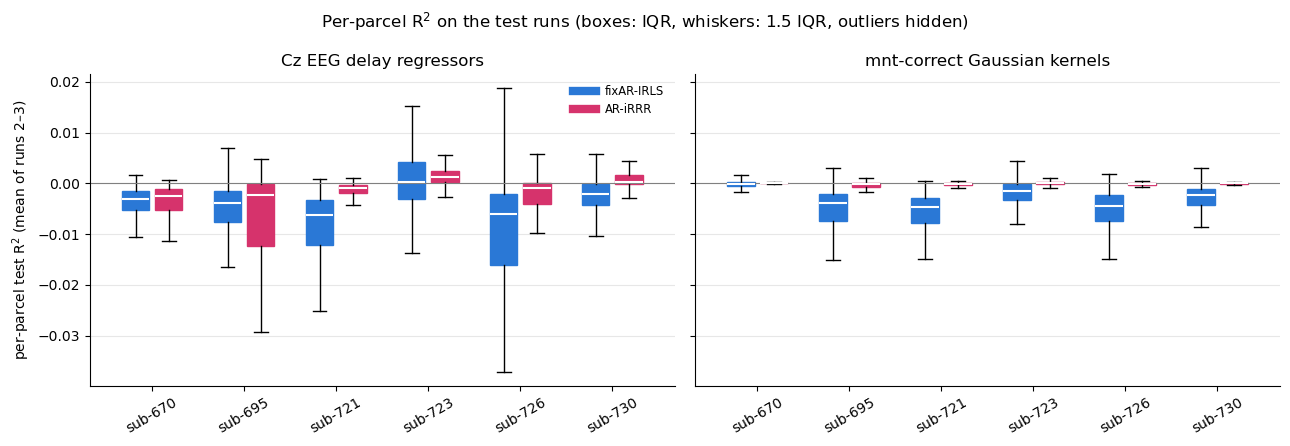

In [6]:
def test_r2_parcel(r, key):
    return np.mean([r[key]['metrics'][rk]['R2_parcel'] for rk in test_runs], axis=0)

fig, axes = plt.subplots(1, len(designs), figsize=(6.5 * len(designs), 4.5), sharey=True)
for ax, d in zip(axes, designs):
    for m_i, (mdl, key) in enumerate([('fixAR-IRLS', 'irls'), ('AR-iRRR', 'irrr')]):
        data = [test_r2_parcel(res[d][s], key) for s in subjects]
        pos = np.arange(len(subjects)) + (m_i - 0.5) * 0.36
        bp = ax.boxplot(data, positions=pos, widths=0.3, patch_artist=True, showfliers=False,
                        medianprops={'color': 'white', 'lw': 1.5})
        for b in bp['boxes']:
            b.set_facecolor(colors[mdl]); b.set_edgecolor(colors[mdl])
        ax.plot([], [], color=colors[mdl], lw=6, label=mdl)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xticks(np.arange(len(subjects)), subjects, rotation=30)
    ax.grid(True, axis='y', alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
    ax.set_title(d)
axes[0].set_ylabel('per-parcel test R$^2$ (mean of runs 2–3)')
axes[0].legend(frameon=False, fontsize='small')
fig.suptitle('Per-parcel R$^2$ on the test runs (boxes: IQR, whiskers: 1.5 IQR, outliers hidden)')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'test_R2_parcel_box.png'), dpi=150)
plt.show()

# same for the training run, for reference
r2p_rows = []
for d in designs:
    for s in subjects:
        for mdl, key in [('fixAR-IRLS', 'irls'), ('AR-iRRR', 'irrr')]:
            tr, te = res[d][s][key]['metrics'][train_run]['R2_parcel'], test_r2_parcel(res[d][s], key)
            r2p_rows.append({'design': d, 'subject': s, 'model': mdl, 'train median': np.median(tr),
                             'test median': np.median(te), 'test: % parcels > 0': 100 * np.mean(te > 0)})
display(pd.DataFrame(r2p_rows).pivot_table(index=['design', 'subject'], columns='model').style.format('{:.4f}'))

**Brain surface.** The maps show per-parcel test R², averaged over subjects, for each design and model. All maps share one color scale. Parcels with a mean R² ≤ 0 are black, and gray parcels were not fitted.

2026-10-14 11:29:55.343 (   7.874s) [    1551BB139400]vtkXOpenGLRenderWindow.:1416  WARN| bad X server connection. DISPLAY=


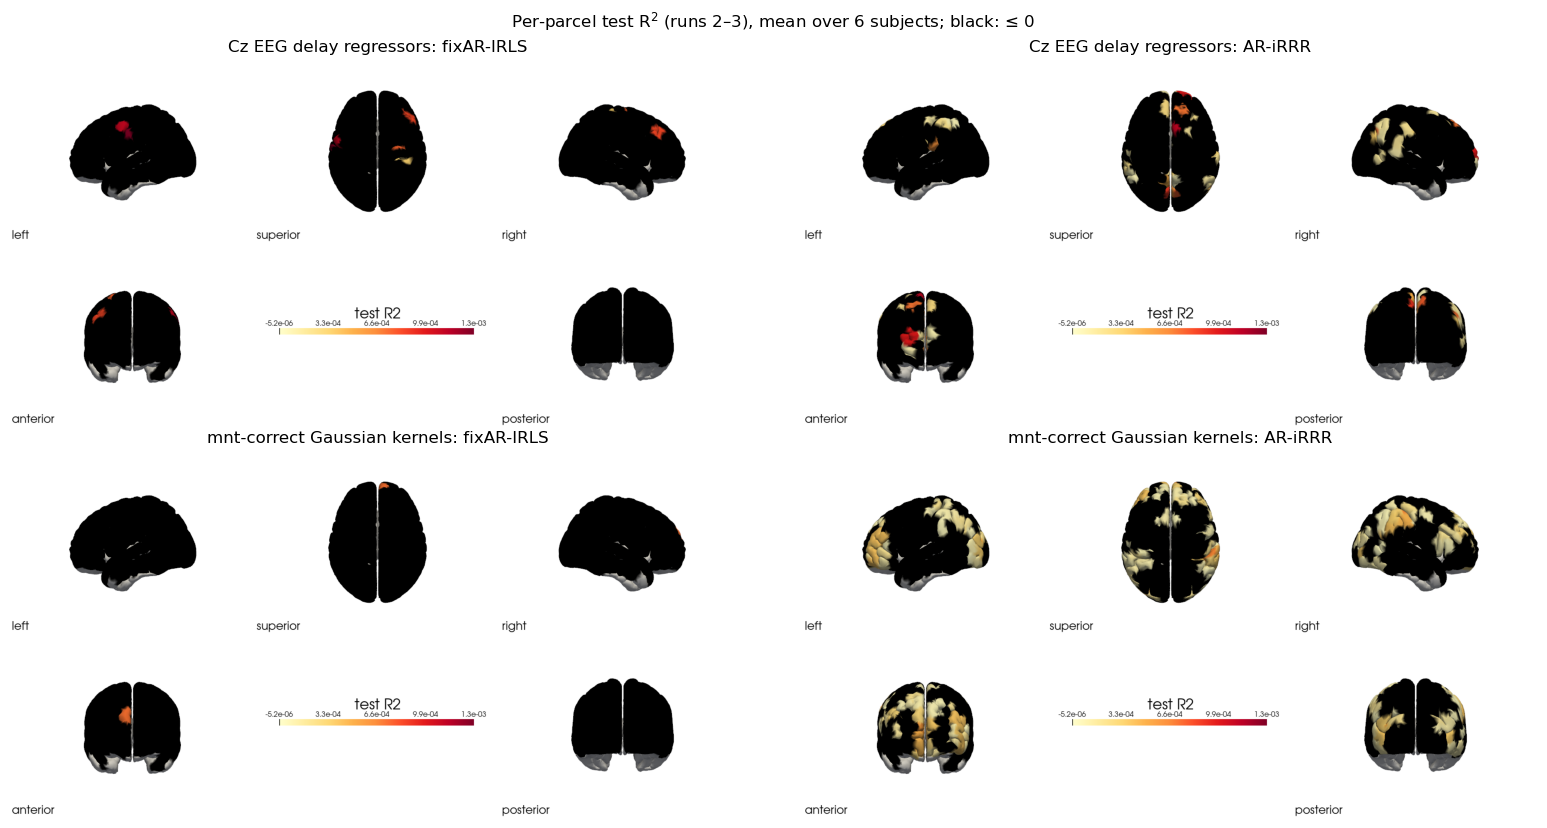

In [7]:
head = cedalion.dot.get_standard_headmodel('icbm152')
vertex_parcel = head.brain.vertices.parcel.values
n_vertex = head.brain.nvertices

def parcel_to_surf(val_by_parcel):
    v = np.array([val_by_parcel.get(p, np.nan) for p in vertex_parcel])
    return xr.DataArray(np.stack([v, np.zeros(n_vertex)], axis=-1), dims=['vertex', 'chromo'],
                        coords={'chromo': ['HbO', 'HbR'], 'is_brain': ('vertex', np.ones(n_vertex, dtype=bool))})

mean_r2 = {(d, mdl): np.mean([test_r2_parcel(res[d][s], key) for s in subjects], axis=0)
           for d in designs for mdl, key in [('fixAR-IRLS', 'irls'), ('AR-iRRR', 'irrr')]}
r2_max = max(np.nanmax(v) for v in mean_r2.values())
r2_black = -r2_max / 255
r2_cmap = ListedColormap(np.vstack([[0, 0, 0, 1], plt.get_cmap('YlOrRd')(np.linspace(0, 1, 255))]))

surf_png = {}
for (d, mdl), v in mean_r2.items():
    tag = f"{designs[d]}_{mdl}".replace(' ', '_')
    path = os.path.join(fig_dir, f'surf_test_r2_{tag}')
    image_recon_multi_view(X_ts=parcel_to_surf(dict(zip(parcels, np.where(v > 0, v, r2_black)))), head=head,
                           cmap=r2_cmap, clim=(r2_black, r2_max), view_type='hbo_brain', title_str='test R2',
                           SAVE=True, filename=path, wdw_size=(1600, 800))
    surf_png[(d, mdl)] = path + '.png'

fig, axes = plt.subplots(len(designs), len(models), figsize=(8 * len(models), 4.2 * len(designs)), squeeze=False)
for r_i, d in enumerate(designs):
    for c_i, mdl in enumerate(models):
        axes[r_i, c_i].imshow(plt.imread(surf_png[(d, mdl)])); axes[r_i, c_i].axis('off')
        axes[r_i, c_i].set_title(f'{d}: {mdl}')
fig.suptitle(f'Per-parcel test R$^2$ (runs 2–3), mean over {len(subjects)} subjects; black: ≤ 0')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'surf_test_r2.png'), dpi=120)
plt.show()

## 6. HRFs

The HRFs are shown at the plot parcel used in the script (`DefaultA_PFCd_1_LH`) and at the 3 parcels nearest to Cz. Distance to Cz is measured from the Cz landmark of the ICBM152 head to the parcel's nearest brain vertex, as in the script. Thin lines are subjects, and the thick line is the mean across subjects.

- **Cz EEG design**: the 15-s FIR response to Cz EEG (M per V). The EEG-locked HRF is estimated at the EEG rate.
- **mnt-correct design**: the evoked HbO response to mnt-correct trials (M), from −2 to 10 s.

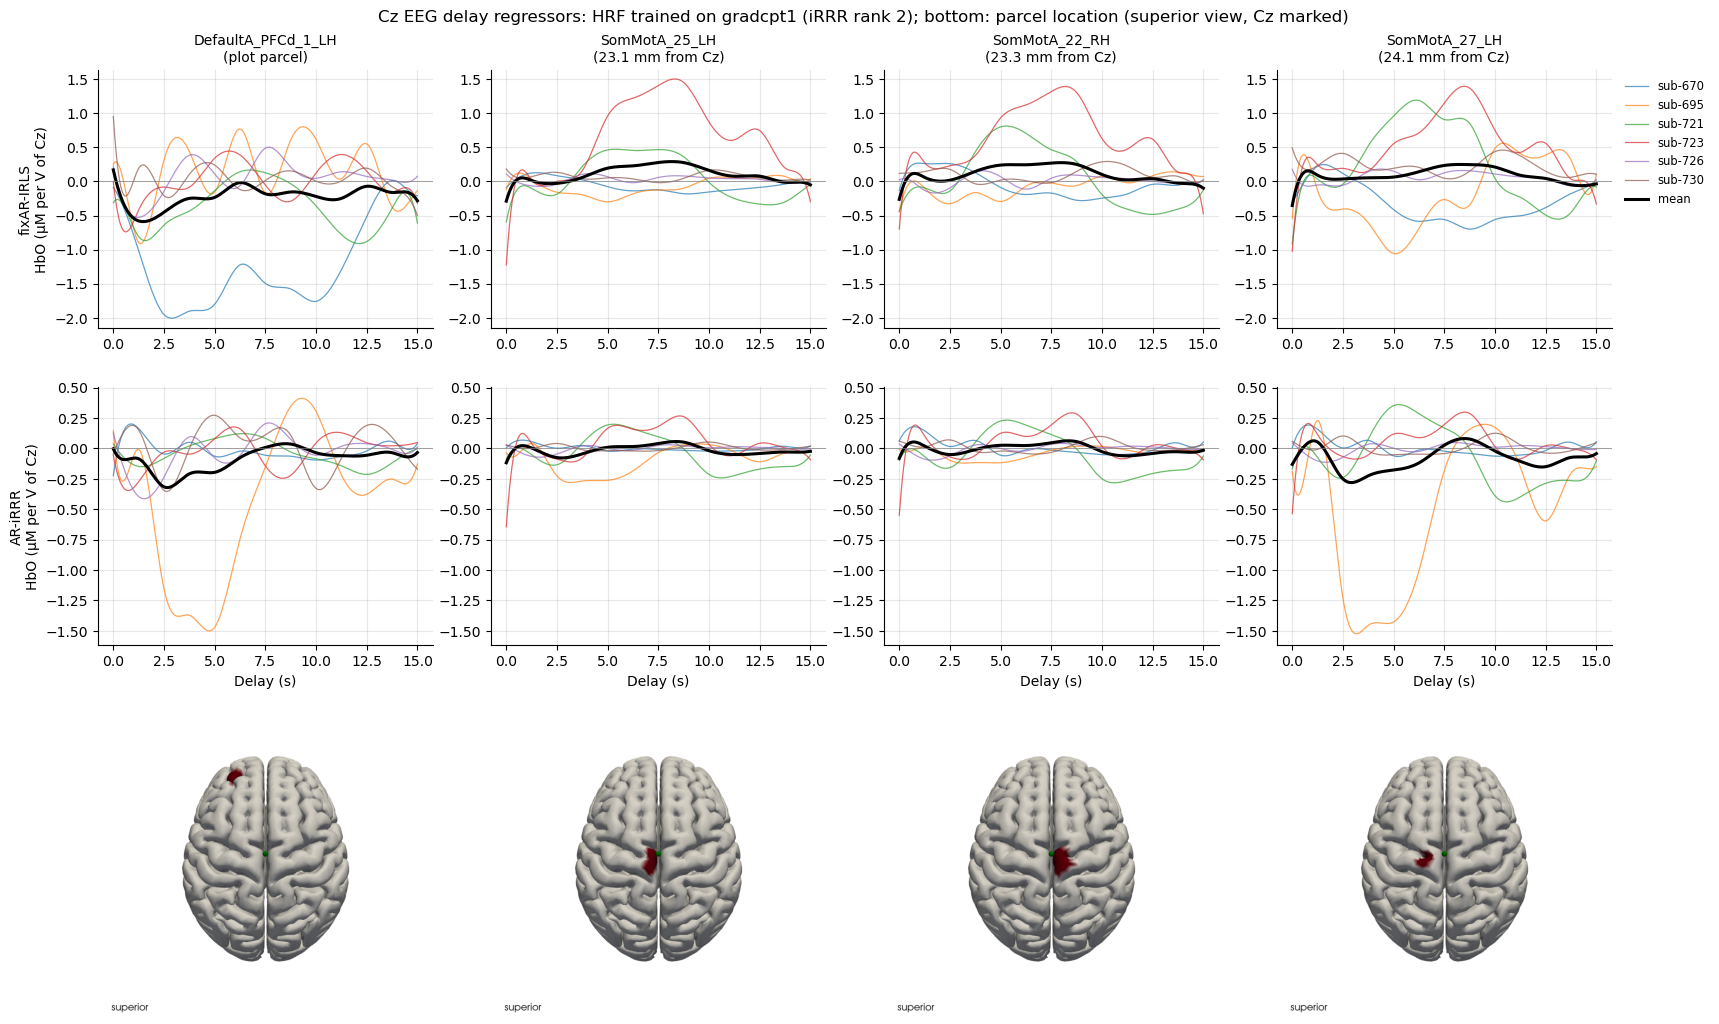

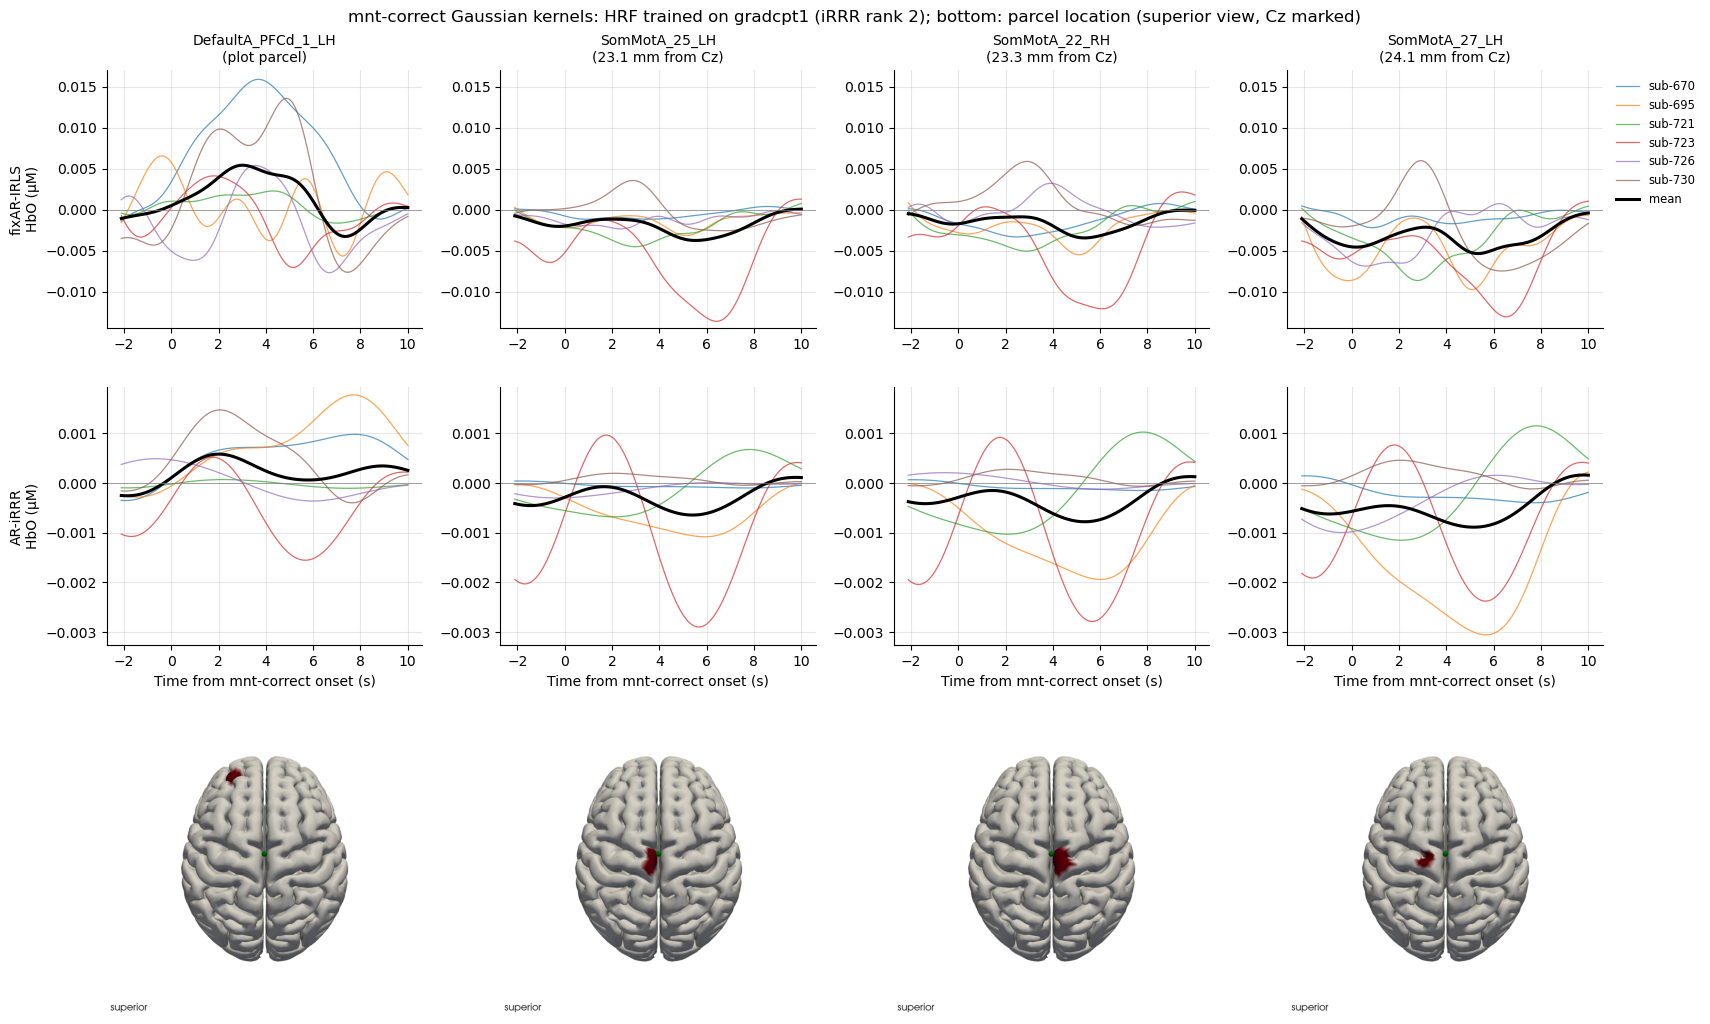

In [8]:
cz_pos = head.landmarks.sel(label='Cz').pint.dequantify().values
vertex_pos = head.brain.vertices.pint.dequantify().values
is_fitted = np.isin(vertex_parcel, parcels)
cz_dist = pd.Series(np.linalg.norm(vertex_pos[is_fitted] - cz_pos, axis=1)).groupby(vertex_parcel[is_fitted]).min()
cz_parcel_dist = cz_dist.drop(plot_parcels, errors='ignore').nsmallest(n_cz_parcels)
hrf_parcels = [(p, 'plot parcel') for p in plot_parcels if p in parcels] + \
              [(p, f'{v:.1f} mm from Cz') for p, v in cz_parcel_dist.items()]

parcel_png = {}
for parcel, _ in hrf_parcels:
    p0, _, _ = image_recon(parcel_to_surf({parcel: 1.0}), head, cmap='Reds', clim=(0, 1), view_type='hbo_brain',
                           view_position='superior', off_screen=True, wdw_size=(800, 800))
    plot_labeled_points(p0, head.landmarks.sel(label=['Cz']))
    parcel_png[parcel] = os.path.join(fig_dir, f'surf_parcel_{parcel}.png')
    p0.screenshot(parcel_png[parcel]); p0.close()

hrf_xlabel = {'Cz EEG delay regressors': 'Delay (s)', 'mnt-correct Gaussian kernels': 'Time from mnt-correct onset (s)'}
hrf_unit = {'Cz EEG delay regressors': (1e6, f'{select_chromo} (µM per V of Cz)'),
            'mnt-correct Gaussian kernels': (1e6, f'{select_chromo} (µM)')}

def plot_hrfs(R, train_label, fname_tag):
    """R: design -> subject -> results dict. One figure per design: rows = models, cols = hrf_parcels."""
    for d in designs:
        scale, ylab = hrf_unit[d]
        n_p = len(hrf_parcels)
        fig, axes = plt.subplots(len(models) + 1, n_p, figsize=(4.3 * n_p, 3.2 * len(models) + 4),
                                 gridspec_kw={'height_ratios': [1] * len(models) + [1.2]}, squeeze=False)
        for m_i, (mdl, key) in enumerate([('fixAR-IRLS', 'irls'), ('AR-iRRR', 'irrr')]):
            for p_i, (parcel, desc) in enumerate(hrf_parcels):
                ax = axes[m_i, p_i]
                hs = []
                for s in subjects:
                    h = R[d][s][key]['betas_eeg']
                    hs.append(h.sel(parcel=parcel).values * scale)
                    ax.plot(h.time.values, hs[-1], color=subj_colors[s], lw=0.9, alpha=0.7, label=s)
                ax.plot(h.time.values, np.mean(hs, axis=0), color='k', lw=2.2, label='mean')
                ax.axhline(0, color='gray', lw=0.5); ax.grid(True, alpha=0.3)
                ax.spines[['top', 'right']].set_visible(False)
                if m_i == 0:
                    ax.set_title(f'{parcel}\n({desc})', fontsize='medium')
                if p_i == 0:
                    ax.set_ylabel(f'{mdl}\n{ylab}')
                if m_i == len(models) - 1:
                    ax.set_xlabel(hrf_xlabel[d])
            # one y-range per model row, covering every panel in the row
            lo = min(ax.get_ylim()[0] for ax in axes[m_i]); hi = max(ax.get_ylim()[1] for ax in axes[m_i])
            for ax in axes[m_i]:
                ax.set_ylim(lo, hi)
        for p_i, (parcel, _) in enumerate(hrf_parcels):
            axes[-1, p_i].imshow(plt.imread(parcel_png[parcel])); axes[-1, p_i].axis('off')
        axes[0, -1].legend(frameon=False, fontsize='small', loc='upper left', bbox_to_anchor=(1.01, 1))
        fig.suptitle(f'{d}: HRF trained on {train_label} (iRRR rank 2); bottom: parcel location (superior view, Cz marked)')
        fig.tight_layout()
        fig.savefig(os.path.join(fig_dir, f'hrf_{fname_tag}_{designs[d]}.png'), dpi=150, bbox_inches='tight')
        plt.show()

plot_hrfs(res, train_run, 'train-gradcpt1')

## 7. Shared temporal components of the rank-2 iRRR fit

The rank-2 iRRR coefficient matrix factors as `C = U S Vᵀ`. Each column of `basis · U · S` is a temporal component, and every parcel's HRF is a weighted sum of the two (weights = rows of `V`).
- The left plots show the two components for each subject, scaled to unit peak. The sign of each is flipped so that its largest-magnitude value is positive, because the sign of an SVD component is arbitrary.
- The right plot shows the share of ‖C‖²_F (the singular value energy) carried by component 1.

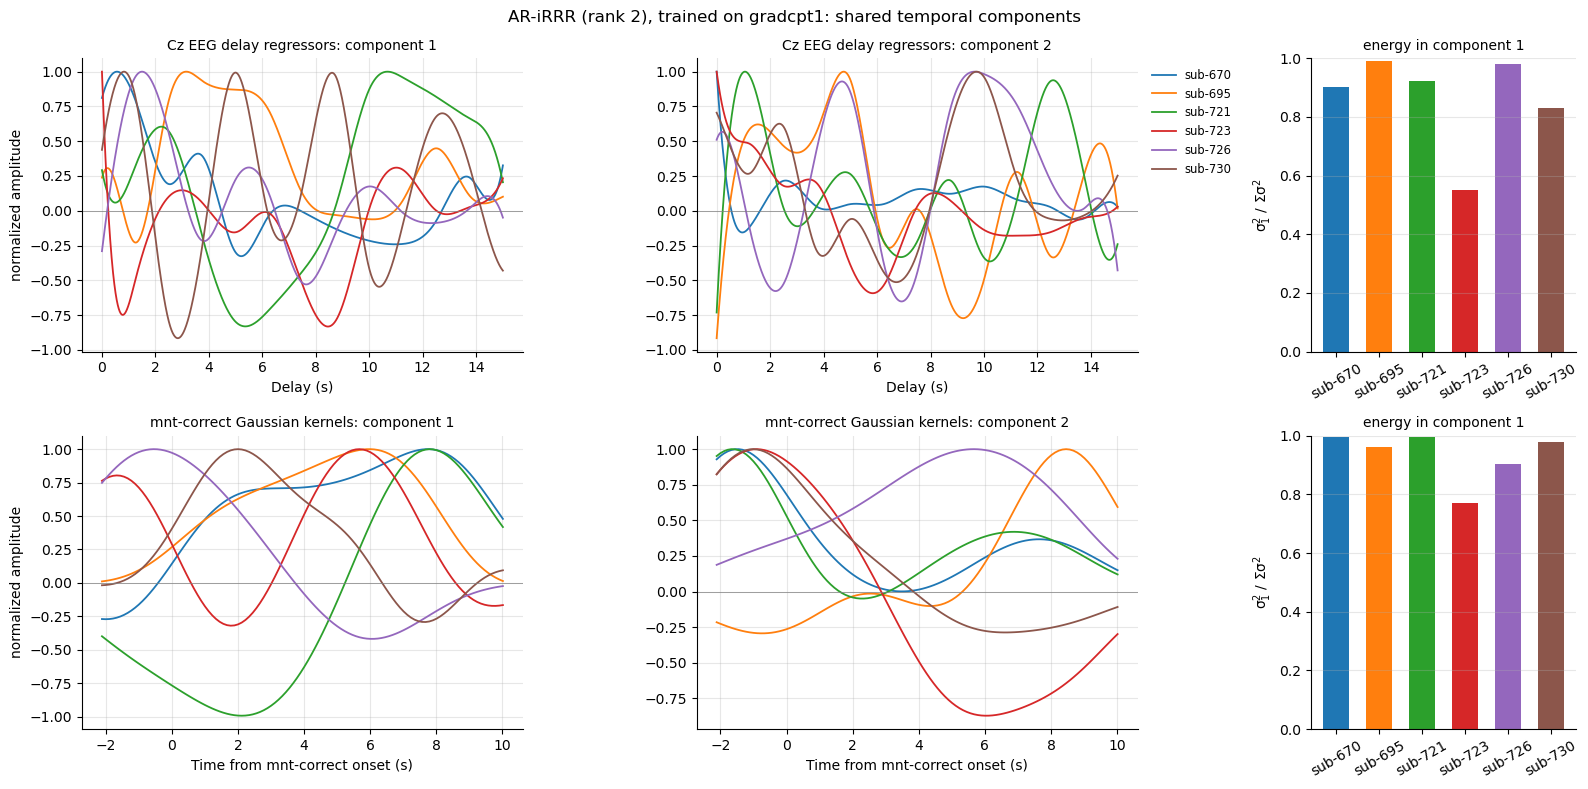

In [9]:
def plot_components(R, train_label, fname_tag):
    """R: design -> subject -> results dict. Rank-2 iRRR temporal components and the energy share of component 1."""
    fig, axes = plt.subplots(len(designs), 3, figsize=(16, 4 * len(designs)), gridspec_kw={'width_ratios': [1, 1, 0.6]})
    for r_i, d in enumerate(designs):
        share = []
        for s in subjects:
            r = R[d][s]
            U, S, Vt = np.linalg.svd(r['irrr']['C'], full_matrices=False)
            comps = r['hrf_basis'] @ U[:, :2] * S[:2]
            for k in range(2):
                c = comps[:, k]
                c = c * np.sign(c[np.argmax(np.abs(c))])
                axes[r_i, k].plot(r['hrf_t'], c / np.abs(c).max(), color=subj_colors[s], lw=1.3, label=s)
            share.append(S[0] ** 2 / np.sum(S ** 2))
        for k in range(2):
            ax = axes[r_i, k]
            ax.axhline(0, color='gray', lw=0.5); ax.grid(True, alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
            ax.set_title(f'{d}: component {k + 1}', fontsize='medium'); ax.set_xlabel(hrf_xlabel[d])
        axes[r_i, 0].set_ylabel('normalized amplitude')
        ax = axes[r_i, 2]
        ax.bar(np.arange(len(subjects)), share, color=[subj_colors[s] for s in subjects], width=0.6)
        ax.set_xticks(np.arange(len(subjects)), subjects, rotation=30); ax.set_ylim(0, 1)
        ax.set_ylabel('σ$_1^2$ / Σσ$^2$'); ax.set_title('energy in component 1', fontsize='medium')
        ax.grid(True, axis='y', alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
    axes[0, 1].legend(frameon=False, fontsize='small', loc='upper left', bbox_to_anchor=(1.01, 1))
    fig.suptitle(f'AR-iRRR (rank 2), trained on {train_label}: shared temporal components')
    fig.tight_layout()
    fig.savefig(os.path.join(fig_dir, f'iRRR_components_{fname_tag}.png'), dpi=150, bbox_inches='tight')
    plt.show()

plot_components(res, train_run, 'train-gradcpt1')

## 8. Observations, Part A (6 subjects, as of 2026-10-14)

1. **Neither model generalizes from `gradcpt1` to `gradcpt2/3`.** The training R² is small: about 0.003–0.03 for the Cz EEG design and ≤ 0.005 for the mnt-correct design. The test R² is about 0 or negative for both models and both designs. Relative PMSE on the test runs is ≥ 1 in most cases, so the regressors do not beat the rank-0 (no-regressor) fit.
2. **AR-iRRR loses less on the test runs than fixAR-IRLS.** It has the higher test R² in 4/6 subjects (Cz EEG) and 6/6 (mnt-correct). This comes mostly from shrinkage pulling the predictions toward zero (the null fit), not from a better predictive HRF: the test R² of AR-iRRR is still ≤ ~0.
3. **Rank sweep.** The best test rank is 0 for most subjects (4/6 Cz EEG, 3/6 mnt-correct). Only sub-723 and sub-730 (Cz EEG) have a positive test R² above 0.001, and it is ≤ 0.0034. Training R² rises with rank while test R² falls, which is the overfitting signature. A rank-2 target is therefore already at or past the best rank for most subjects.
4. **HRFs and components are not consistent across subjects.** The rank-2 temporal components differ in shape and timing between subjects for both designs. In most subjects the first component carries > 80% of ‖C‖². The subject-mean HRFs near Cz are small and flat.

# Part B: trained on all runs (in-sample)

## 9. What changes in the pipeline

`cmp_fixAR-IRLS_AR-iRRR_single-subj_all-runs.py` uses the same inputs, the same per-run preprocessing (1a–1b) and the same models (1d) as Part A. Only the following differs:

| Step | Part A (single run) | Part B (all runs) |
|---|---|---|
| Order per run | … → GSR → **whiten → truncate** | … → GSR → **truncate → whiten** |
| Whitening kernel | OLS residuals of `Y ~ 1 + X` over the full span of `gradcpt1` | OLS residuals of `Y ~ X` + one intercept per run, over the **truncated** trial windows of **all three runs**. The autocovariances are summed over runs, so no lag crosses a run boundary. |
| Whitening applied | to each run's full span, then truncated | to each truncated run separately |
| `Y_scale` | std of whitened `gradcpt1` | std of whitened `Y` over all runs |
| Training data | whitened `gradcpt1` | the three whitened runs, concatenated |
| λ₁ (iRRR) | smallest λ₁ giving rank 2, on `gradcpt1` | smallest λ₁ giving rank 2, on all runs |
| Metrics | train (`gradcpt1`) and test (`gradcpt2/3`) | **in-sample** for each run and pooled over all runs (`all`) |

Because every metric in Part B is in-sample, a positive R² here does not show that the model generalizes. Also, the two parts use different whitening filters and `Y_scale`, so their R² and PMSE values are on slightly different footings. The comparisons in sections 11 and 14 should be read with that in mind.

In [10]:
designs_all = {   # design label -> model_name of the all-runs script
    'Cz EEG delay regressors':      'cont_EEG_cz_postWhiten_train-allRuns',
    'mnt-correct Gaussian kernels': 'mnt-correct_gauss_postWhiten_train-allRuns',
}
score_keys = run_keys + ['all']

missing = [(s, mn) for s in subjects for mn in designs_all.values()
           if not os.path.exists(os.path.join(eeg_der_dir, s, f'{s}_{mn}_cmp_fixAR-IRLS_AR-iRRR.pkl'))]
if missing:
    raise FileNotFoundError(f'all-runs results missing (run cmp_fixAR-IRLS_AR-iRRR_single-subj_all-runs.py): {missing}')
res_all = {d: {} for d in designs_all}   # design -> subject -> results dict
for d, mn in designs_all.items():
    for s in subjects:
        with open(os.path.join(eeg_der_dir, s, f'{s}_{mn}_cmp_fixAR-IRLS_AR-iRRR.pkl'), 'rb') as f:
            res_all[d][s] = pickle.load(f)
        assert list(res_all[d][s]['train_runs']) == run_keys
        assert np.array_equal(res_all[d][s]['parcels'], parcels)
print(f'all-runs results loaded for {len(subjects)} subjects')

all-runs results loaded for 6 subjects


## 10. Fit summary (all runs)
The columns are as in section 2. `Y_scale` and `irrr_lam1` are shown next to their Part A values.

In [11]:
fit_rows_all = []
for d in designs:
    for s in subjects:
        r, rA = res_all[d][s], res[d][s]
        fit_rows_all.append({'design': d, 'subject': s,
                             'Y_scale (M)': r['Y_scale'], 'Y_scale, Part A (M)': rA['Y_scale'],
                             'irrr_lam1': r['irrr']['irrr_lam1'], 'irrr_lam1, Part A': rA['irrr']['irrr_lam1'],
                             'bisected': not np.isclose(grid, r['irrr']['irrr_lam1']).any(),
                             'IRLS rank': r['irls']['rank'], 'iRRR rank': np.linalg.matrix_rank(r['irrr']['C'])})
display(pd.DataFrame(fit_rows_all).set_index(['design', 'subject']).style.format(
    {'Y_scale (M)': '{:.3g}', 'Y_scale, Part A (M)': '{:.3g}', 'irrr_lam1': '{:.3g}', 'irrr_lam1, Part A': '{:.3g}'}))

## 11. In-sample performance per run and pooled

This uses the same layout as section 3, but every run is part of the training data. `all` is the pooled fit over the three runs, which is what both models minimize. Relative PMSE is again divided by the rank-0 iRRR fit (Ŷ = μ) on the same run.

The first table shows the pooled (`all`) in-sample R² and the difference between the models. The second table puts each model's Part B in-sample R² on `gradcpt2/3` next to its Part A test R² on the same runs. The gap shows how much of the fit on those runs comes from having trained on them.

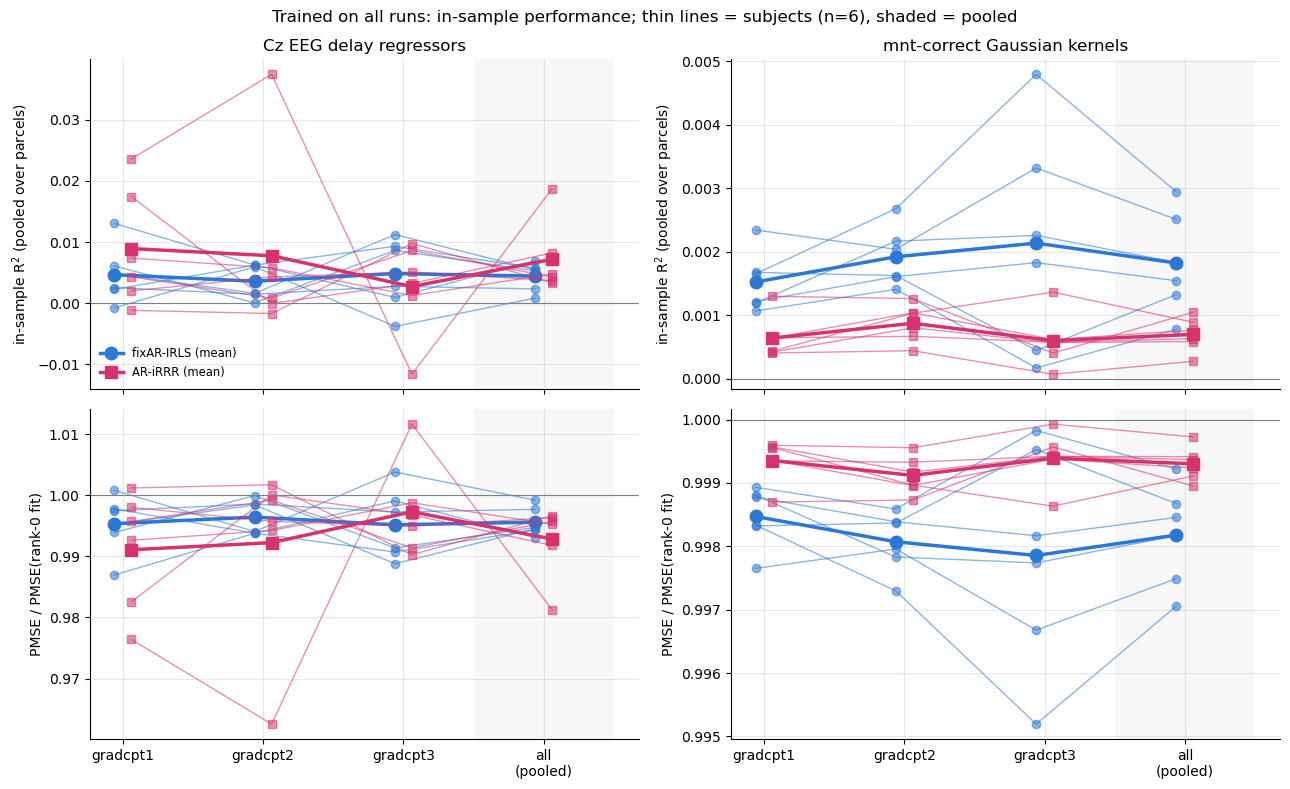

In [12]:
perf_rows_all = []
for d in designs:
    for s in subjects:
        r = res_all[d][s]
        for mdl, key in [('fixAR-IRLS', 'irls'), ('AR-iRRR', 'irrr')]:
            for rk in score_keys:
                m = r[key]['metrics'][rk]
                perf_rows_all.append({'design': d, 'subject': s, 'model': mdl, 'run': rk,
                                      'R2': m['R2'], 'PMSE': m['PMSE'], 'rel PMSE': m['PMSE'] / null_pmse(r, rk),
                                      'median parcel R2': np.median(m['R2_parcel'])})
perf_all_df = pd.DataFrame(perf_rows_all)

fig, axes = plt.subplots(2, len(designs), figsize=(6.5 * len(designs), 8), sharex=True)
x = np.arange(len(score_keys))
for c, d in enumerate(designs):
    for row, (metric, ylab) in enumerate([('R2', 'in-sample R$^2$ (pooled over parcels)'), ('rel PMSE', 'PMSE / PMSE(rank-0 fit)')]):
        ax = axes[row, c]
        for mdl in models:
            dx = -0.06 if mdl == 'fixAR-IRLS' else 0.06
            for s in subjects:
                v = perf_all_df.query('design == @d and subject == @s and model == @mdl').set_index('run').loc[score_keys, metric]
                ax.plot(x + dx, v.values, color=colors[mdl], marker=markers[mdl], ms=6, lw=1, alpha=0.55)
            mean = perf_all_df.query('design == @d and model == @mdl').groupby('run')[metric].mean().loc[score_keys]
            ax.plot(x + dx, mean.values, color=colors[mdl], marker=markers[mdl], ms=9, lw=2.5, label=f'{mdl} (mean)')
        ax.axhline(0 if metric == 'R2' else 1, color='gray', lw=0.8)
        ax.axvspan(2.5, 3.5, color='gray', alpha=0.06, lw=0)
        ax.grid(True, alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
        ax.set_ylabel(ylab)
        if row == 0:
            ax.set_title(d)
    axes[1, c].set_xticks(x, run_keys + ['all\n(pooled)'])
axes[0, 0].legend(frameon=False, fontsize='small')
fig.suptitle(f'Trained on all runs: in-sample performance; thin lines = subjects (n={len(subjects)}), shaded = pooled')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'allRuns_insample_R2_PMSE.png'), dpi=150)
plt.show()

In [13]:
pooled = perf_all_df[perf_all_df.run == 'all'].pivot_table(index=['design', 'subject'], columns='model', values=['R2', 'rel PMSE'])
pooled_tbl = pd.DataFrame({'R2: fixAR-IRLS': pooled[('R2', 'fixAR-IRLS')], 'R2: AR-iRRR': pooled[('R2', 'AR-iRRR')],
                           'ΔR2 (iRRR − IRLS)': pooled[('R2', 'AR-iRRR')] - pooled[('R2', 'fixAR-IRLS')],
                           'Δ rel PMSE (iRRR − IRLS)': pooled[('rel PMSE', 'AR-iRRR')] - pooled[('rel PMSE', 'fixAR-IRLS')]})
r2_cols_b = ['R2: fixAR-IRLS', 'R2: AR-iRRR', 'ΔR2 (iRRR − IRLS)']
lim_r2_b = np.abs(pooled_tbl[r2_cols_b].values).max()
lim_pmse_b = np.abs(pooled_tbl['Δ rel PMSE (iRRR − IRLS)'].values).max()
display(pooled_tbl.style.format('{:.4f}')
        .background_gradient(cmap='RdBu_r', vmin=-lim_r2_b, vmax=lim_r2_b, subset=r2_cols_b, axis=None)
        .background_gradient(cmap='RdBu', vmin=-lim_pmse_b, vmax=lim_pmse_b, subset=['Δ rel PMSE (iRRR − IRLS)'])
        .set_caption('Pooled in-sample fit over all runs. R² columns: red = positive. Δ columns: red = AR-iRRR better '
                     '(higher R², lower PMSE), blue = fixAR-IRLS better'))

# the same runs (gradcpt2/3) scored out-of-sample (Part A) and in-sample (Part B)
insamp = perf_all_df[perf_all_df.run.isin(test_runs)].groupby(['design', 'subject', 'model'])['R2'].mean().unstack('model')
outsamp = perf_df[perf_df.set == 'test'].groupby(['design', 'subject', 'model'])['R2'].mean().unstack('model')
gap_tbl = pd.concat({'Part A: test R2': outsamp, 'Part B: in-sample R2': insamp}, axis=1)[
    [('Part A: test R2', 'fixAR-IRLS'), ('Part B: in-sample R2', 'fixAR-IRLS'),
     ('Part A: test R2', 'AR-iRRR'), ('Part B: in-sample R2', 'AR-iRRR')]]
lim_gap = np.abs(gap_tbl.values).max()
display(gap_tbl.style.format('{:.4f}').background_gradient(cmap='RdBu_r', vmin=-lim_gap, vmax=lim_gap, axis=None)
        .set_caption('R² on gradcpt2/3 (mean of the two runs): not trained on them (Part A) vs trained on them (Part B). '
                     'Red = positive, blue = negative'))

## 12. iRRR rank sweep (in-sample)

Pooled in-sample R² over all runs against iRRR rank, one line per subject. ✕ marks fixAR-IRLS at its full rank, and the red dashed line is the chosen rank (2). In-sample R² rises with rank, so this plot shows how much of the full-rank fit rank 2 keeps, not which rank generalizes.

fixAR-IRLS can sit **below** the iRRR curve even at full rank. It minimizes a robust Tukey-biweight loss, not squared error, so it is not the least-squares fit, and R² is a squared-error measure. Its intercept is also fixed at 0. The table therefore compares rank 2 with iRRR's own full-rank fit (its smallest λ₁, which is close to unpenalized least squares).

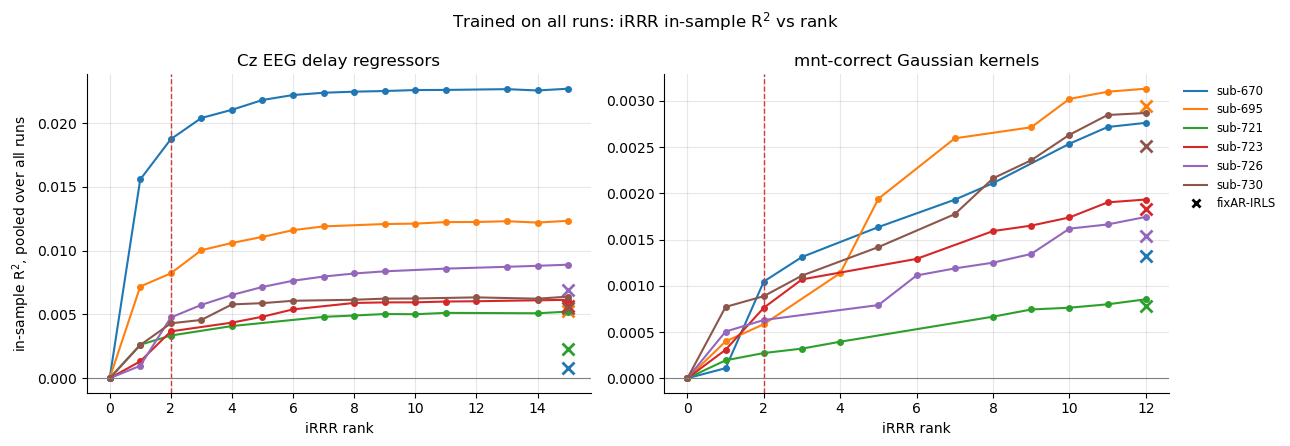

In [14]:
fig, axes = plt.subplots(1, len(designs), figsize=(6.5 * len(designs), 4.5))
for ax, d in zip(axes, designs):
    for s in subjects:
        r = res_all[d][s]
        bpr = best_per_rank(r['irrr_scan'])
        ax.plot(list(bpr), [f['metrics']['all']['R2'] for f in bpr.values()], color=subj_colors[s], lw=1.5,
                marker='o', ms=4, label=s)
        ax.plot(r['irls']['rank'], r['irls']['metrics']['all']['R2'], marker='x', ms=9, mew=2, color=subj_colors[s], ls='none')
    ax.axvline(2, color='#d03b3b', ls='--', lw=1)
    ax.axhline(0, color='gray', lw=0.8)
    ax.grid(True, alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
    ax.set_xlabel('iRRR rank'); ax.set_title(d)
axes[0].set_ylabel('in-sample R$^2$, pooled over all runs')
handles = [Line2D([], [], color=subj_colors[s], lw=1.5, label=s) for s in subjects] + [
    Line2D([], [], color='k', marker='x', mew=2, ls='none', label='fixAR-IRLS')]
axes[-1].legend(handles=handles, frameon=False, fontsize='small', loc='upper left', bbox_to_anchor=(1.01, 1))
fig.suptitle('Trained on all runs: iRRR in-sample R$^2$ vs rank')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'allRuns_iRRR_rank_sweep.png'), dpi=150, bbox_inches='tight')
plt.show()

keep_rows = []
for d in designs:
    for s in subjects:
        r = res_all[d][s]
        full = min(r['irrr_scan'], key=lambda f: f['lam1'])   # smallest lam1 = least shrinkage
        keep_rows.append({'design': d, 'subject': s, 'iRRR full-rank R2': full['metrics']['all']['R2'],
                          'iRRR full rank': full['rank'], 'iRRR rank-2 R2': r['irrr']['metrics']['all']['R2'],
                          'rank 2 / full rank (%)': 100 * r['irrr']['metrics']['all']['R2'] / full['metrics']['all']['R2'],
                          'fixAR-IRLS R2': r['irls']['metrics']['all']['R2']})
display(pd.DataFrame(keep_rows).set_index(['design', 'subject']).style.format(
    {'iRRR full-rank R2': '{:.4f}', 'iRRR rank-2 R2': '{:.4f}', 'rank 2 / full rank (%)': '{:.0f}', 'fixAR-IRLS R2': '{:.4f}'}))

## 13. Per-parcel in-sample R² on the brain surface

These maps use the same layout as section 5, but show per-parcel R² pooled over all runs (in-sample), averaged over subjects. All four maps share one color scale. Black marks R² ≤ 0, and gray parcels were not fitted.

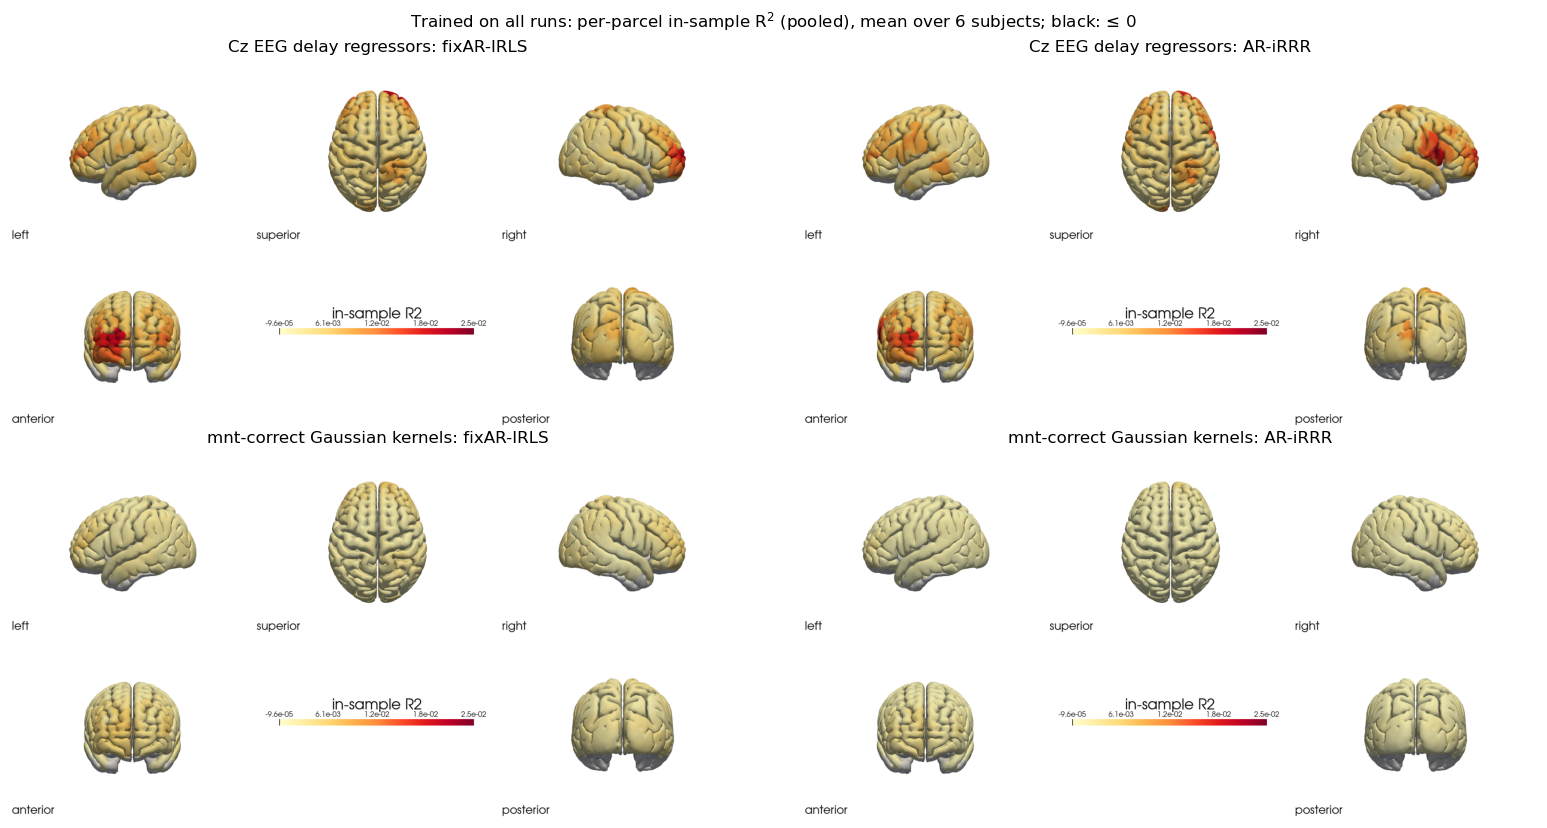

In [15]:
mean_r2_all = {(d, mdl): np.mean([res_all[d][s][key]['metrics']['all']['R2_parcel'] for s in subjects], axis=0)
               for d in designs for mdl, key in [('fixAR-IRLS', 'irls'), ('AR-iRRR', 'irrr')]}
r2_max_b = max(np.nanmax(v) for v in mean_r2_all.values())
r2_black_b = -r2_max_b / 255

surf_png_all = {}
for (d, mdl), v in mean_r2_all.items():
    tag = f"{designs_all[d]}_{mdl}".replace(' ', '_')
    path = os.path.join(fig_dir, f'surf_insample_r2_{tag}')
    image_recon_multi_view(X_ts=parcel_to_surf(dict(zip(parcels, np.where(v > 0, v, r2_black_b)))), head=head,
                           cmap=r2_cmap, clim=(r2_black_b, r2_max_b), view_type='hbo_brain', title_str='in-sample R2',
                           SAVE=True, filename=path, wdw_size=(1600, 800))
    surf_png_all[(d, mdl)] = path + '.png'

fig, axes = plt.subplots(len(designs), len(models), figsize=(8 * len(models), 4.2 * len(designs)), squeeze=False)
for r_i, d in enumerate(designs):
    for c_i, mdl in enumerate(models):
        axes[r_i, c_i].imshow(plt.imread(surf_png_all[(d, mdl)])); axes[r_i, c_i].axis('off')
        axes[r_i, c_i].set_title(f'{d}: {mdl}')
fig.suptitle(f'Trained on all runs: per-parcel in-sample R$^2$ (pooled), mean over {len(subjects)} subjects; black: ≤ 0')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'allRuns_surf_insample_r2.png'), dpi=120)
plt.show()

## 14. HRFs (all runs)

The HRFs use the same parcels and layout as section 6, but the models were fit on all runs.

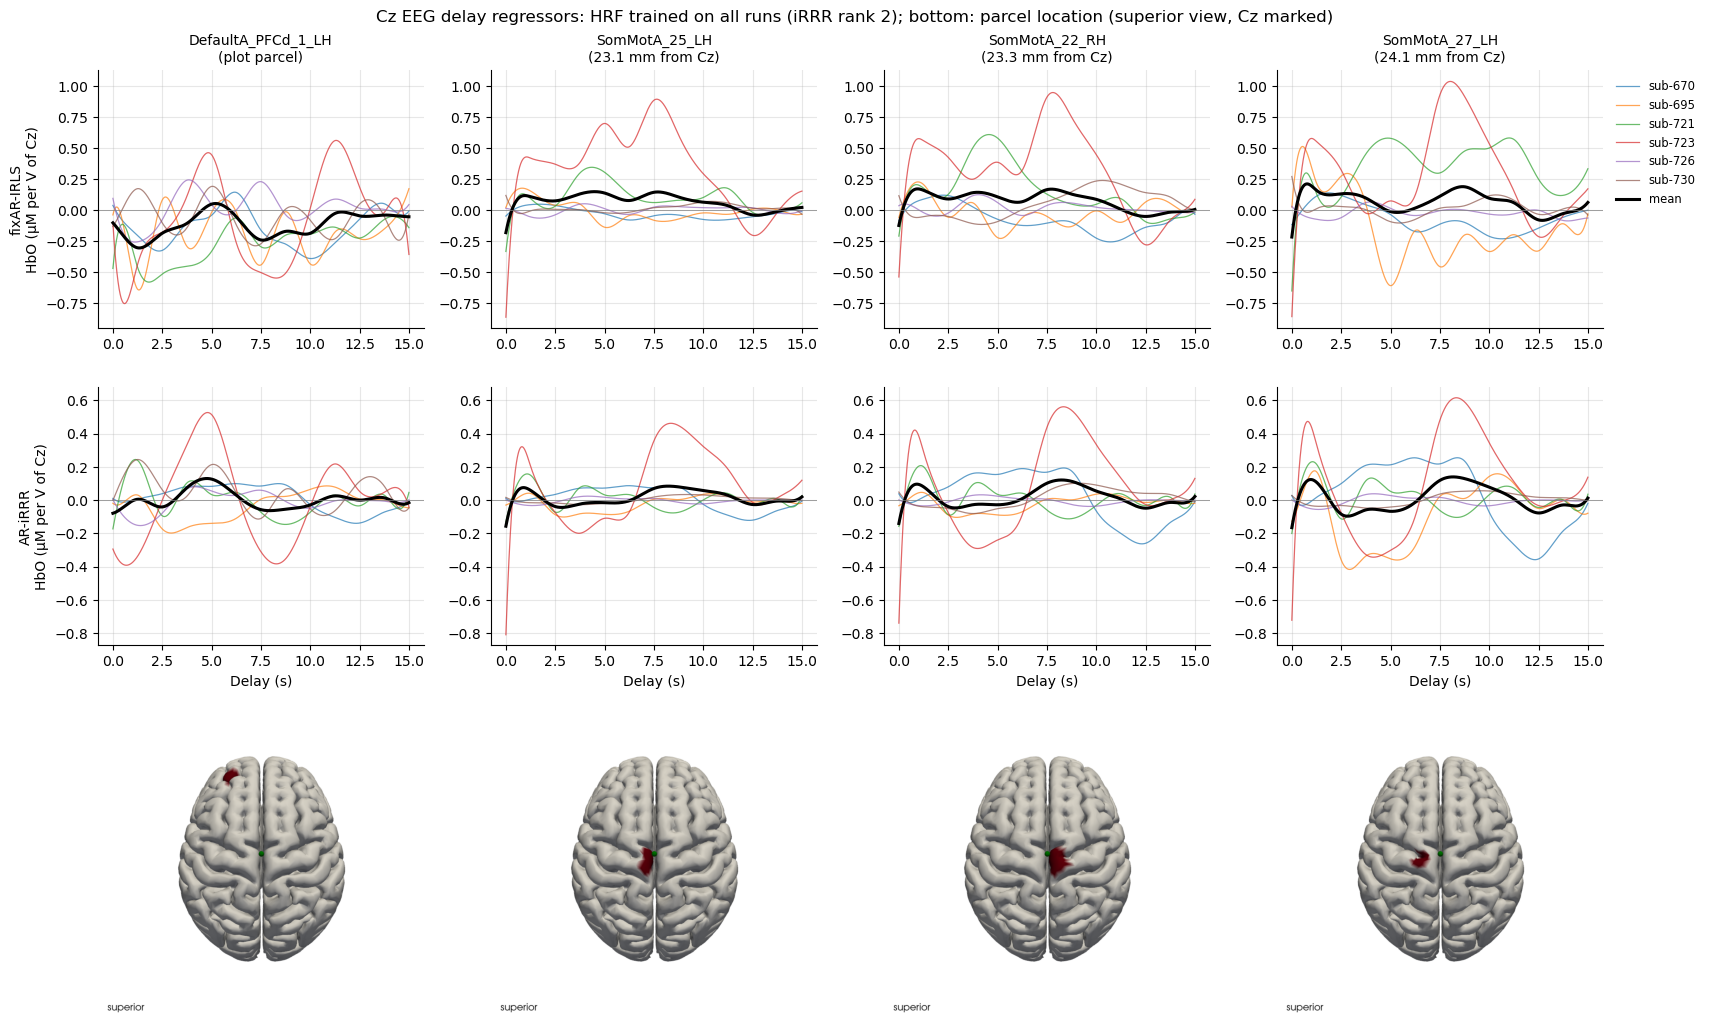

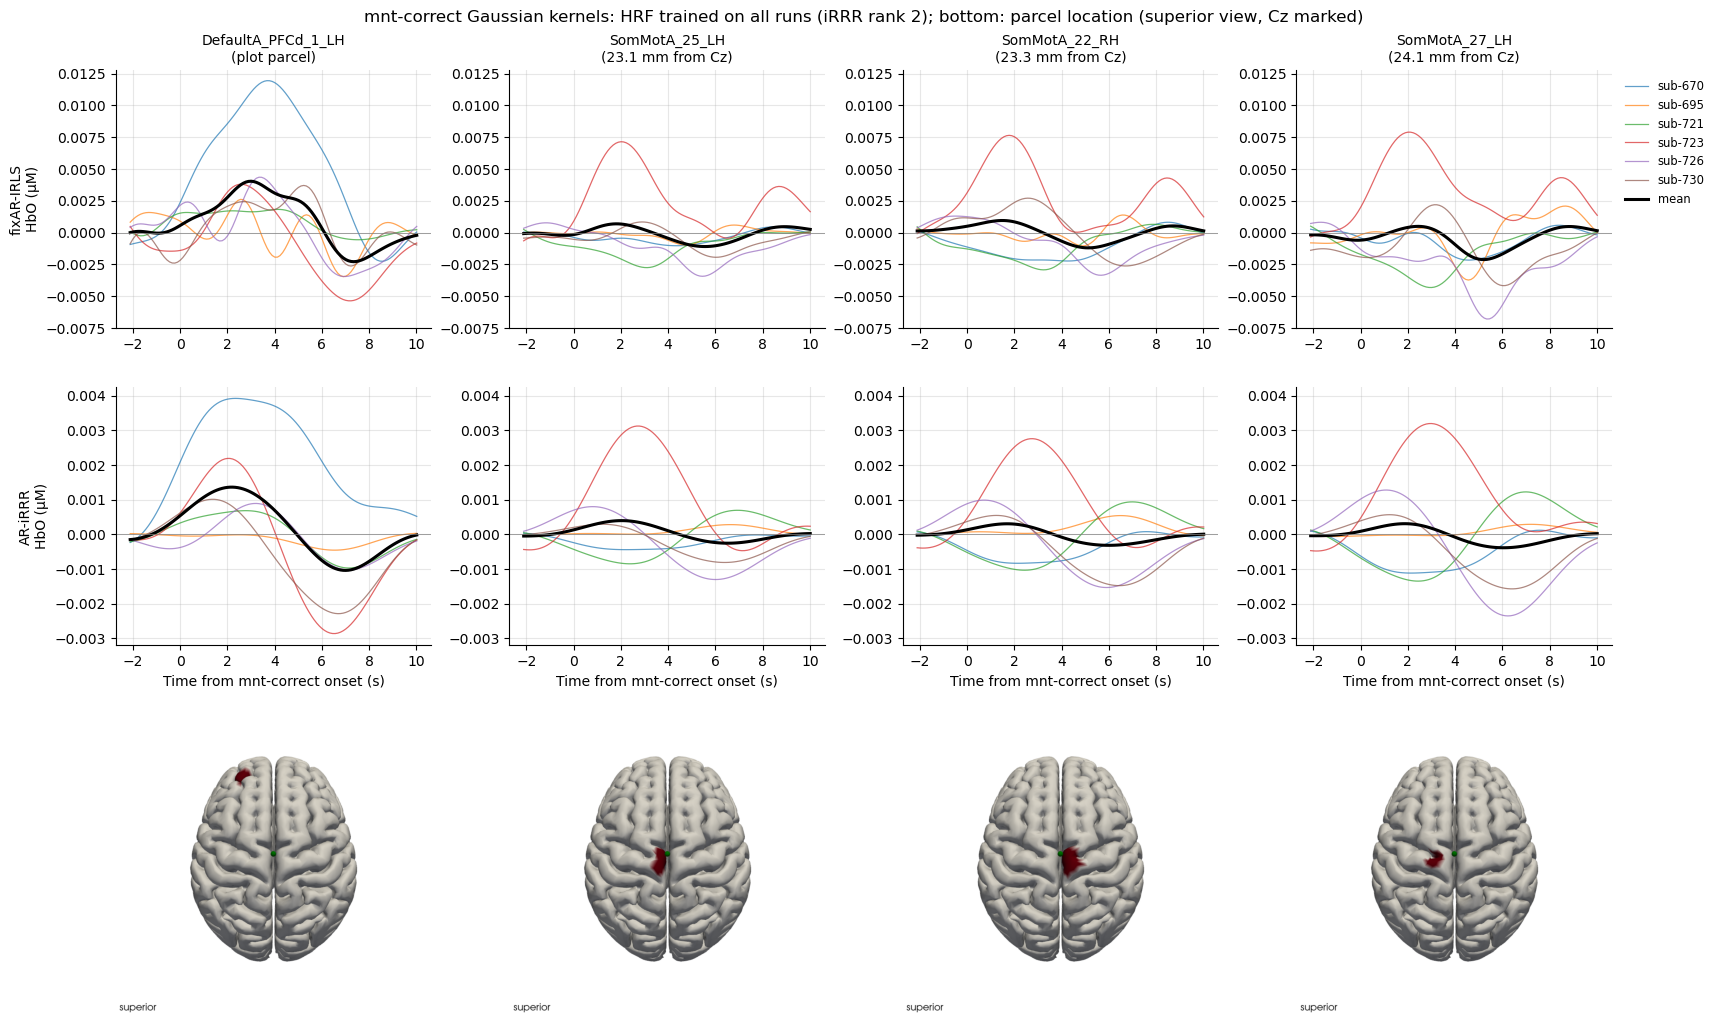

In [16]:
plot_hrfs(res_all, 'all runs', 'train-allRuns')

**Agreement with Part A.** For each subject, design and model, the plot correlates the HRF trained on `gradcpt1` (Part A) with the HRF trained on all runs (Part B), parcel by parcel, over the HRF time axis. Each point is the median of the 417 per-parcel correlations. `gradcpt1` is one third of the Part B training data, so the two fits are not independent. Values near 1 mean adding runs 2–3 barely changed the HRF, and values near 0 mean the run-1 HRF did not hold up.

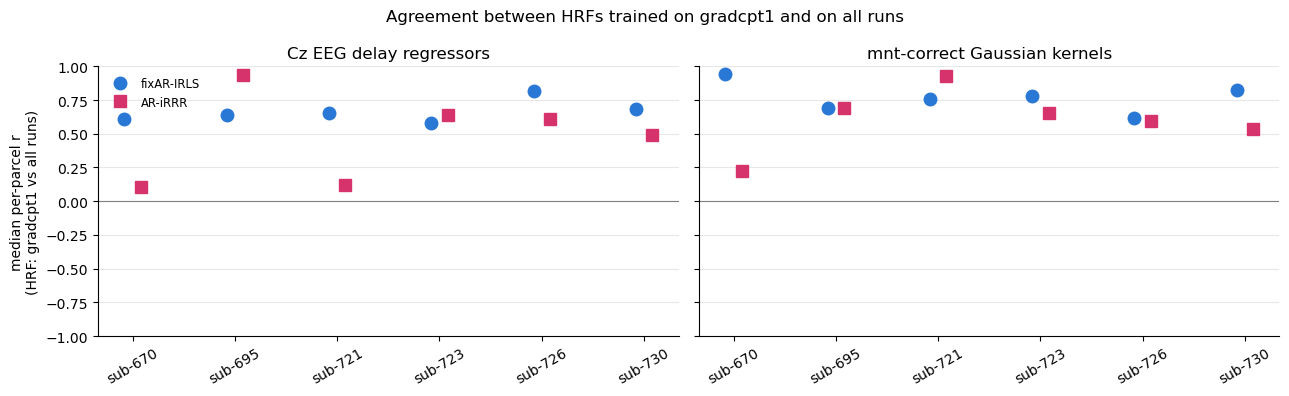

In [17]:
def rowwise_corr(a, b):
    a = a - a.mean(1, keepdims=True); b = b - b.mean(1, keepdims=True)
    return (a * b).sum(1) / np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))

agree_rows = []
for d in designs:
    for s in subjects:
        for mdl, key in [('fixAR-IRLS', 'irls'), ('AR-iRRR', 'irrr')]:
            hA = res[d][s][key]['betas_eeg'].sel(parcel=parcels).values
            hB = res_all[d][s][key]['betas_eeg'].sel(parcel=parcels).values
            r_p = rowwise_corr(hA, hB)
            agree_rows.append({'design': d, 'subject': s, 'model': mdl, 'median r': np.nanmedian(r_p),
                               '% parcels r > 0.5': 100 * np.nanmean(r_p > 0.5)})
agree_df = pd.DataFrame(agree_rows)

fig, axes = plt.subplots(1, len(designs), figsize=(6.5 * len(designs), 4), sharey=True)
for ax, d in zip(axes, designs):
    for mdl in models:
        v = agree_df.query('design == @d and model == @mdl').set_index('subject').loc[subjects, 'median r']
        ax.plot(np.arange(len(subjects)) + (-0.08 if mdl == 'fixAR-IRLS' else 0.08), v.values, ls='none',
                marker=markers[mdl], ms=9, color=colors[mdl], label=mdl)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xticks(np.arange(len(subjects)), subjects, rotation=30); ax.set_ylim(-1, 1)
    ax.grid(True, axis='y', alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
    ax.set_title(d)
axes[0].set_ylabel('median per-parcel r\n(HRF: gradcpt1 vs all runs)')
axes[0].legend(frameon=False, fontsize='small')
fig.suptitle('Agreement between HRFs trained on gradcpt1 and on all runs')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'hrf_agreement_gradcpt1_vs_allRuns.png'), dpi=150)
plt.show()
display(agree_df.pivot_table(index=['design', 'subject'], columns='model').style.format('{:.2f}')
        .background_gradient(cmap='RdBu_r', vmin=-1, vmax=1, subset=[c for c in agree_df.pivot_table(index=['design', 'subject'], columns='model').columns if c[0] == 'median r']))

## 15. Shared temporal components of the rank-2 iRRR fit (all runs)

The components are computed as in section 7, but from the all-runs fit.

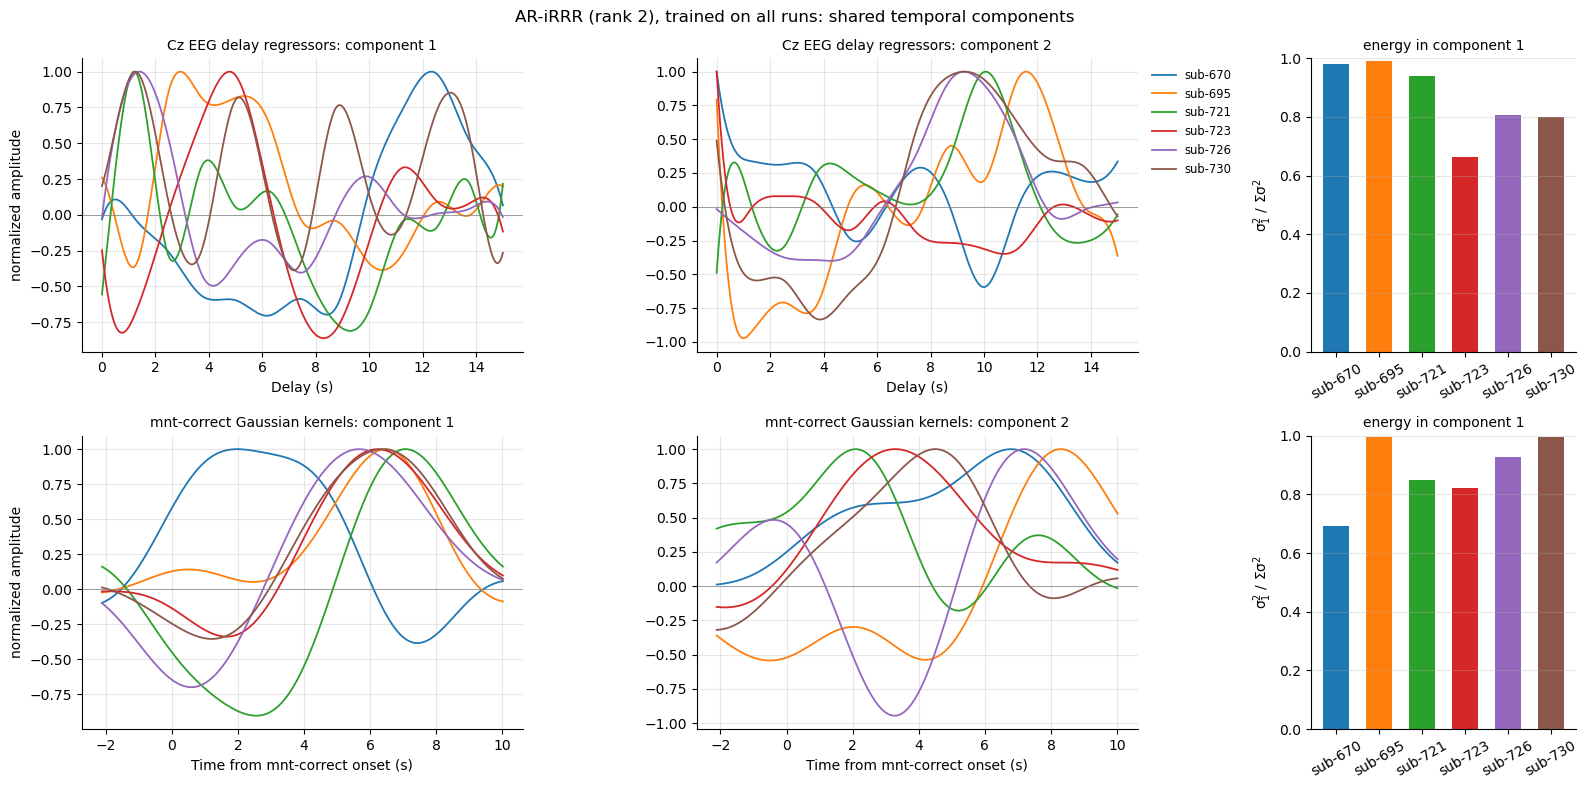

In [18]:
plot_components(res_all, 'all runs', 'train-allRuns')

## 16. Observations, Part B (6 subjects, as of 2026-10-14)

1. **Even in-sample, the fits are small.** Pooled R² over all runs is 0.001–0.019 for the Cz EEG design and ≤ 0.003 for the mnt-correct design. Relative PMSE stays just below 1: the regressors explain under 2% (Cz EEG) or 0.3% (mnt-correct) of the whitened variance, even on the data they were fit to.
2. **Training on runs 2–3 is what makes them fit.** On `gradcpt2/3`, Part B in-sample R² is positive for every subject and model, while the Part A test R² on the same runs is mostly negative (section 11, second table). So the gap between the two parts is the overfitting gap; it is not evidence of a shared response.
3. **Which model fits better depends on the design.**
   - *Cz EEG*: rank-2 AR-iRRR has the higher pooled R² in 3/6 subjects (sub-670, 695, 721), and fixAR-IRLS in the other 3. In those 3 subjects, fixAR-IRLS is below even the iRRR rank-1 fit, because its robust loss is not least squares. sub-670 is extreme: fixAR-IRLS R² = 0.0008, against 0.023 for iRRR at full rank.
   - *mnt-correct*: fixAR-IRLS is higher in 6/6 subjects. Rank 2 keeps only 19–39% of the iRRR full-rank R² here, against 54–83% for Cz EEG. The trial-locked fit is spread over more temporal components.
4. **The HRFs only partly agree with Part A.** The median per-parcel correlation between the `gradcpt1` HRF and the all-runs HRF is 0.58–0.94 for fixAR-IRLS, even though `gradcpt1` is a third of the Part B data. For AR-iRRR it varies more, 0.11–0.94. It is lowest where the rank-2 subspace changed (Cz EEG: sub-670 and sub-721; mnt-correct: sub-670). The rank-2 components still differ between subjects, as in Part A.
5. **Choice of λ₁.** With more data, the rank-2 λ₁ moves for most subjects. For the mnt-correct design it is smaller in 5/6 subjects, and 3 of those needed bisection because no grid value gave exactly rank 2.